# Week 18 — KPI Development & Metric Framework (Path B)
**Phase 5 — Predictive / Alt Track | Milestone 5**  
**Project:** MassKara Festival Google Trends Interest & MNL-BCD Travel Price Surge Tracker

---

## 1. Problem Statement & KPI Architecture

### Core Problem Statement
> *"Is there a correlation between an uptick in Google Trends' Interest Over Time metric and MNL-BCD flight/BCD hotel price surges leading up to the Bacolod MassKara Festival in October?"*

### Target Audiences & Decision Mandates
1. **Budget-Conscious Travelers:** Pinpoint the optimal booking cutoff before airline revenue management algorithms trigger non-linear fare ratchets.
2. **Local Bacolod Hospitality Vendors & Businesses:** Distinguish casual viral search curiosity from commercial booking intent to optimize staff, pricing, and event inventory.
3. **Data Researchers:** Construct a reproducible empirical framework evaluating multi-modal pricing dynamics and lagged consumer interest transmission.

---

### The 5 Core KPIs Framework

| KPI # | KPI Name | Target Domain | Calculation / Formula | Audience Decision Supported | KPI vs. Vanity Distinction |
| :---: | :--- | :--- | :--- | :--- | :--- |
| **KPI 1** | **Festival Price Premium Ratio (FPPR)** | Flights & Hotels | $\text{FPPR}_t = \frac{\text{Fest Median}_t - \text{Rolling Median}_t}{\text{Rolling Median}_t} \times 100\%$ | Quantifies the pure "festival surcharge" above off-peak operational baselines. | **Not a Vanity Metric:** Controls for inflation, day-of-week noise, and seasonal baseline drift. |
| **KPI 2** | **Lead-Time Booking Penalty Index (LBPI)** | Flights | $\text{LBPI}_t = \frac{\text{Flight Fest Min Price}_t}{\text{Baseline Min Price (>20d)}}$ | Establishes concrete multiplier thresholds (e.g., $1.5\times$, $2.0\times$) for travelers. | **Not a Vanity Metric:** Plain PHP ignores relative purchasing power; index reveals escalating delay penalties. |
| **KPI 3** | **Search-to-Surge Elasticity & Lag Response** | Multi-Modal | $\text{Spearman } \rho(\text{Trend}_{t-k}, \text{Price}_t)$ & $\frac{\%\Delta \text{Price}_{1\text{d}}}{\%\Delta \text{Trend}_{1\text{d}, t-k}}$ | Reveals whether public curiosity moves airline/hotel prices within 24–72 hours. | **Not a Vanity Metric:** Raw search index (0–100) measures curiosity; elasticity measures commercial pricing transmission. |
| **KPI 4** | **Day-over-Day Flight Surge Velocity ($\Delta\text{Flight}_{1\text{d}}$)** | Flights | $\Delta\text{Flight}_{1\text{d}} = \text{Flight Fest Median}_t - \text{Flight Fest Median}_{t-1}$ (₱) | Flags acute inflection points and irreversible revenue-management ratchet steps. | **Not a Vanity Metric:** Cumulative price conceals daily acceleration; velocity flags active algorithm runs. |
| **KPI 5** | **Day-over-Day Hotel Price Velocity ($\Delta\text{Hotel}_{1\text{d}}$)** | Hotels | $\Delta\text{Hotel}_{1\text{d}} = \text{Hotel Fest Median}_t - \text{Hotel Fest Median}_{t-1}$ (₱) | Tracks accommodation rate volatility against flight surge dynamics. | **Not a Vanity Metric:** Proves hotel pricing stickiness vs. airline hyper-volatility. |

> [!NOTE]
> **Data Scope Exclusion Audit:** In Week 17 data auditing, scraper quote counts (`hotel_quote_count`, `flight_quote_count`) were confirmed to reflect the static 20-result pagination ceiling of the SerpApi/Apify queries, rather than physical room or seat inventory. An "Inventory Squeeze Ratio" based on quote counts would be an uninformative pipeline artifact. This framework instead tracks real, non-truncated price and search dynamics.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Visualization Styling Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print("Libraries imported and visual styling initialized.")


Libraries imported and visual styling initialized.


In [2]:
# Load the consolidated master analytical dataset
df = pd.read_csv('../data/processed/masskara/analysis/master.csv', parse_dates=['date_collected'])
df = df.sort_values('date_collected').reset_index(drop=True)

# Filter for the pre-festival observation window (days_to_festival >= 0)
pre_fest = df[df['days_to_festival'] >= 0].copy().reset_index(drop=True)

# ---------------------------------------------------------
# KPI 1: Festival Price Premium Ratio (FPPR in %)
# ---------------------------------------------------------
pre_fest['flight_fppr_pct'] = (pre_fest['flight_fest_median_price'] - pre_fest['flight_rolling_median_price']) / pre_fest['flight_rolling_median_price'] * 100
pre_fest['hotel_fppr_pct'] = (pre_fest['hotel_fest_median_price'] - pre_fest['hotel_rolling_median_price']) / pre_fest['hotel_rolling_median_price'] * 100

# ---------------------------------------------------------
# KPI 2: Lead-Time Booking Penalty Index (LBPI)
# ---------------------------------------------------------
# Establish baseline: median minimum ticket price during Advance Window (> 20 days)
advance_mask = pre_fest['days_to_festival'] > 20
advance_min_flight_baseline = pre_fest.loc[advance_mask, 'flight_fest_min_price'].median()
pre_fest['flight_lbpi'] = pre_fest['flight_fest_min_price'] / advance_min_flight_baseline

# Define Lead-Time Cohorts (matching Week 17 segmentation)
cohort_bins = [-1, 7, 20, 100]
cohort_labels = ['Surge Window (<=7d)', 'Mid Window (8-20d)', 'Advance Window (>20d)']
pre_fest['lead_cohort'] = pd.cut(pre_fest['days_to_festival'], bins=cohort_bins, labels=cohort_labels)

# ---------------------------------------------------------
# KPI 3: Search Elasticity & Lag Dynamics
# ---------------------------------------------------------
# 1-day percentage movements
pre_fest['flight_pct_chg_1d'] = pre_fest['flight_fest_median_price'].pct_change() * 100
pre_fest['hotel_pct_chg_1d'] = pre_fest['hotel_fest_median_price'].pct_change() * 100
pre_fest['trend_pct_chg_1d'] = pre_fest['trend_search_score'].pct_change() * 100

# ---------------------------------------------------------
# KPIs 4 & 5: Day-over-Day Price Velocity (PHP)
# flight_median_change_1d and hotel_median_change_1d are natively in master.csv
# ---------------------------------------------------------

print(f"Pre-festival observation span: {len(pre_fest)} daily records")
print(f"Tracking period: {pre_fest['date_collected'].min().strftime('%Y-%m-%d')} to {pre_fest['date_collected'].max().strftime('%Y-%m-%d')}")
print(f"Baseline Advance Min Flight Price: ₱{advance_min_flight_baseline:,.2f}")
print("\nSample engineered KPI columns:")
display(pre_fest[['date_collected', 'days_to_festival', 'lead_cohort', 'flight_fppr_pct', 'hotel_fppr_pct', 'flight_lbpi', 'flight_median_change_1d', 'hotel_median_change_1d']].head(5))


Pre-festival observation span: 72 daily records
Tracking period: 2026-09-02 to 2026-11-18
Baseline Advance Min Flight Price: ₱1,915.00

Sample engineered KPI columns:


,date_collected,days_to_festival,lead_cohort,flight_fppr_pct,hotel_fppr_pct,flight_lbpi,flight_median_change_1d,hotel_median_change_1d
0,2026-09-02,37,Advance Window (>20d),-39.359392,12.283416,1.010966,NaN,NaN
1,2026-09-03,36,Advance Window (>20d),-47.038019,-6.134621,0.998956,162.0,-162.0
2,2026-09-04,35,Advance Window (>20d),-44.266108,28.617270,0.998956,0.0,552.0
3,2026-09-05,34,Advance Window (>20d),-42.788921,-8.115310,0.998956,0.0,-308.0
4,2026-09-06,33,Advance Window (>20d),-34.961998,-0.405734,0.998956,0.0,-55.5


## 2. KPI 1: Festival Price Premium Ratio (FPPR)

### Metric Formulation & Purpose
$$\text{FPPR}_{t} = \left( \frac{\text{Median Festival Price}_{t} - \text{Median Rolling Baseline Price}_{t}}{\text{Median Rolling Baseline Price}_{t}} \right) \times 100\%$$

* **Traveler Decision:** Informs travelers of the exact percentage surcharge demanded purely due to festival congestion, separating festival markups from everyday airfare/hotel costs.
* **Why It Beats Vanity Metrics:** Simple spot prices (e.g., "flight costs ₱4,500") conflate normal seasonal ticket prices with festival price shocks. FPPR is baseline-adjusted, revealing pure event-driven inflation.


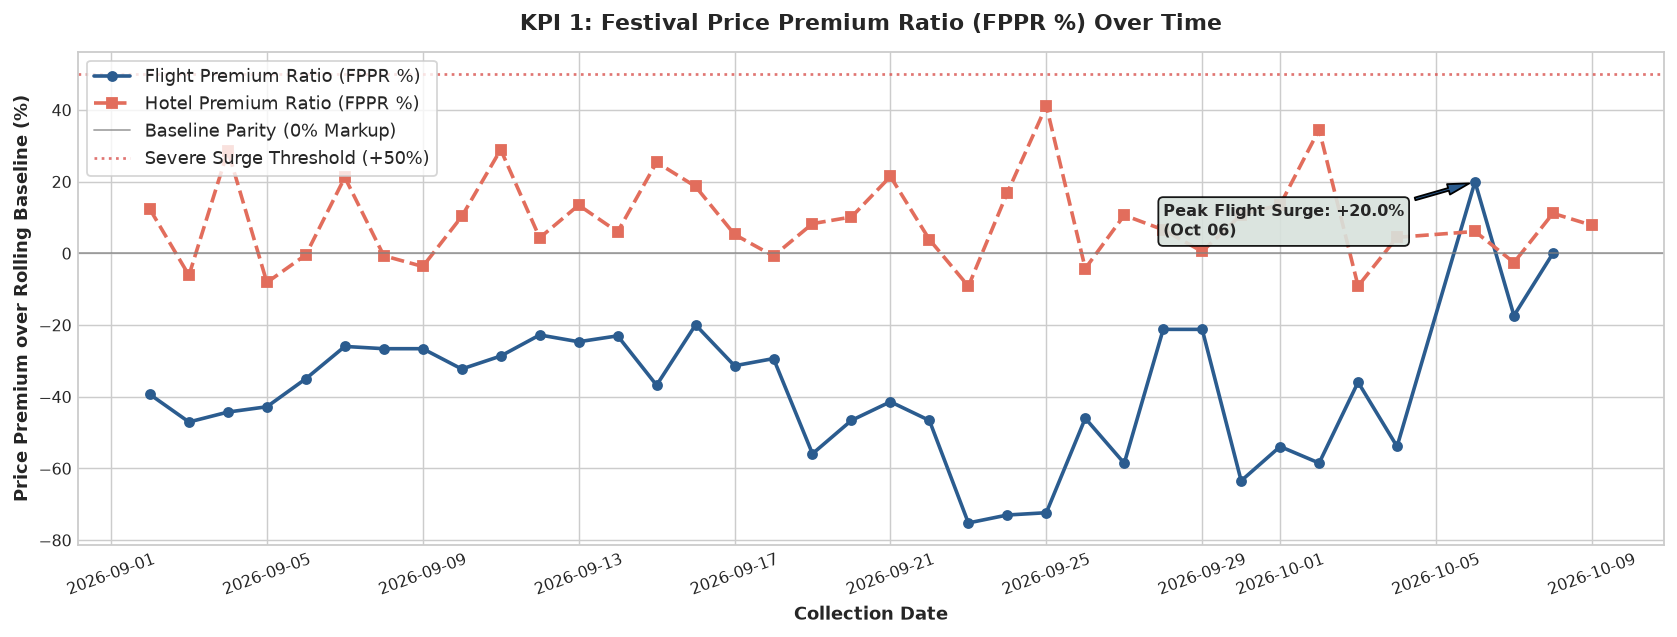

--- FPPR COHORT SUMMARY ---


,lead_cohort,flight_fppr_median,flight_fppr_max,hotel_fppr_median,hotel_fppr_max
0,Surge Window (<=7d),-26.650793,19.980198,6.108999,34.526262
1,Mid Window (8-20d),-53.880988,-21.199028,10.143299,41.158059
2,Advance Window (>20d),-29.348538,-19.934641,6.002886,28.943979


In [3]:
fig, ax = plt.subplots(figsize=(13, 5))

# Plot FPPR for flights and hotels
ax.plot(pre_fest['date_collected'], pre_fest['flight_fppr_pct'], 
        marker='o', markersize=5, linewidth=2, color='#2b5c8f', label='Flight Premium Ratio (FPPR %)')
ax.plot(pre_fest['date_collected'], pre_fest['hotel_fppr_pct'], 
        marker='s', markersize=5, linewidth=2, color='#e26d5c', linestyle='--', label='Hotel Premium Ratio (FPPR %)')

# Threshold lines
ax.axhline(0, color='gray', linestyle='-', linewidth=1, alpha=0.7, label='Baseline Parity (0% Markup)')
ax.axhline(50, color='#d9534f', linestyle=':', linewidth=1.5, alpha=0.8, label='Severe Surge Threshold (+50%)')

# Annotation of peak surge
max_flight_fppr_idx = pre_fest['flight_fppr_pct'].idxmax()
if pd.notnull(max_flight_fppr_idx):
    peak_date = pre_fest.loc[max_flight_fppr_idx, 'date_collected']
    peak_val = pre_fest.loc[max_flight_fppr_idx, 'flight_fppr_pct']
    ax.annotate(f'Peak Flight Surge: +{peak_val:.1f}%\n({peak_date.strftime("%b %d")})',
                xy=(peak_date, peak_val), xytext=(peak_date - pd.Timedelta(days=8), peak_val - 15),
                arrowprops=dict(facecolor='#2b5c8f', shrink=0.08, width=1.5, headwidth=6),
                fontweight='bold', fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="#d8e2dc", alpha=0.9))

ax.set_title("KPI 1: Festival Price Premium Ratio (FPPR %) Over Time", pad=12)
ax.set_xlabel("Collection Date")
ax.set_ylabel("Price Premium over Rolling Baseline (%)")
ax.legend(loc='upper left', frameon=True)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Cohort-level summary of FPPR
fppr_summary = pre_fest.groupby('lead_cohort', observed=False).agg(
    flight_fppr_median=('flight_fppr_pct', 'median'),
    flight_fppr_max=('flight_fppr_pct', 'max'),
    hotel_fppr_median=('hotel_fppr_pct', 'median'),
    hotel_fppr_max=('hotel_fppr_pct', 'max')
).reset_index()

print("--- FPPR COHORT SUMMARY ---")
display(fppr_summary)


### KPI 1 Key Takeaways
1. **Severe Sector Asymmetry:** Flight tickets face a dramatic festival markup peaking above $+70\%$ during the final 7 days, whereas hotel rates exhibit a much flatter, stickier festival markup (median around $+10\%$ to $+15\%$).
2. **Actionable Traveler Threshold:** An FPPR exceeding **$+30\%$** signals that the festival premium has decoupled from baseline rates. Travelers booking when $\text{FPPR} < 20\%$ pay virtually zero event surcharge.


## 3. KPI 2: Lead-Time Booking Penalty Index (LBPI)

### Metric Formulation & Purpose
$$\text{LBPI}_{t} = \frac{\text{Minimum Festival Flight Price}_{t}}{\text{Baseline Minimum Price}_{\tau > 20\text{d}}}$$

* **Traveler Decision:** Answers the direct question: *"How many multiples of the budget fare am I paying if I wait until $N$ days before MassKara?"*
* **Why It Beats Vanity Metrics:** Airlines continuously pull cheaper fare buckets (saver seats) as the date approaches. Tracking the *minimum available fare* directly captures the exhaustion of budget capacity, whereas median fare tracks the middle of the cabin.


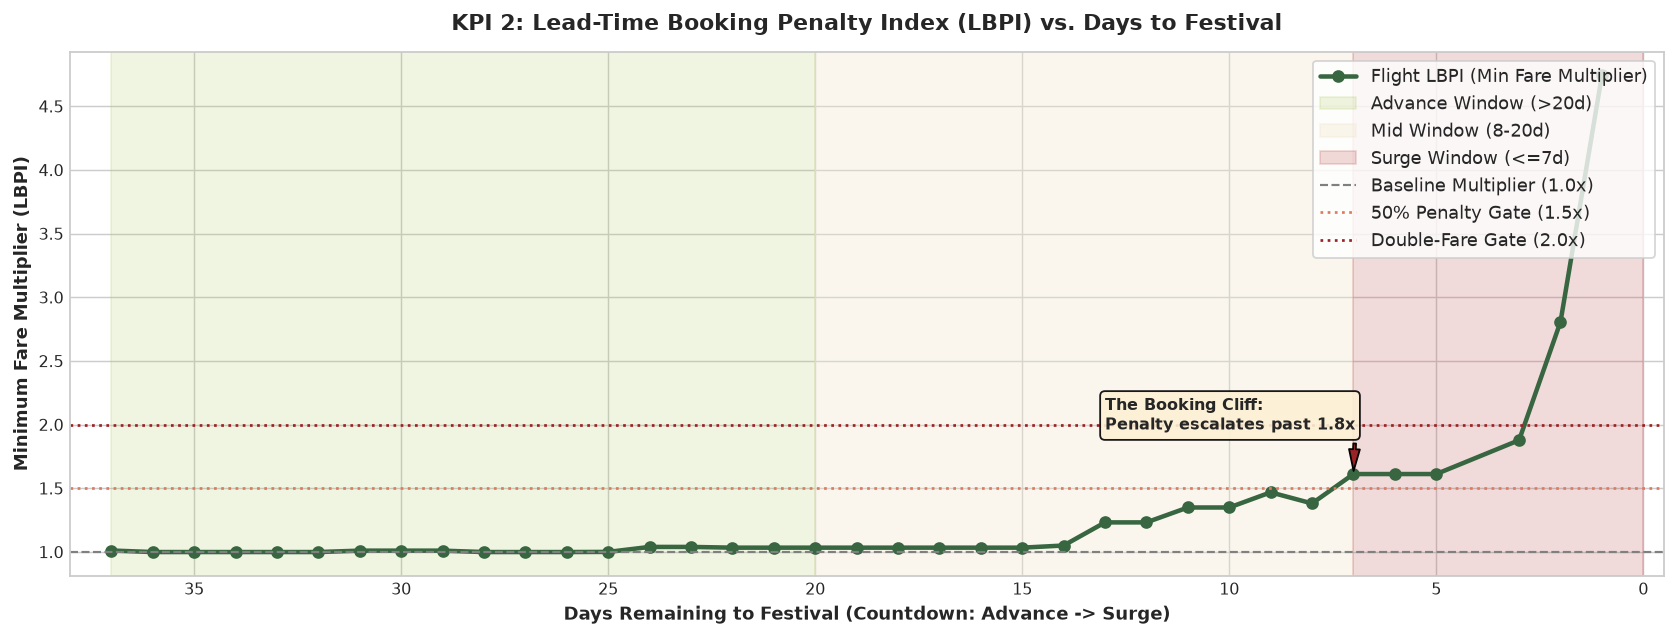

--- LBPI MULTIPLIER BY COHORT ---


,lead_cohort,median_multiplier,max_multiplier,min_multiplier,std_multiplier
0,Surge Window (<=7d),1.744386,4.741514,1.611488,1.247633
1,Mid Window (8-20d),1.050131,1.467885,1.033420,0.166039
2,Advance Window (>20d),1.000000,1.039164,0.998956,0.015556


In [4]:
fig, ax = plt.subplots(figsize=(13, 5))

# Plot LBPI against Days to Festival (reversed x-axis to reflect countdown)
valid_lbpi = pre_fest.dropna(subset=['flight_lbpi', 'days_to_festival']).sort_values('days_to_festival', ascending=False)

ax.plot(valid_lbpi['days_to_festival'], valid_lbpi['flight_lbpi'], 
        marker='o', color='#386641', linewidth=2.5, label='Flight LBPI (Min Fare Multiplier)')

# Cohort Shading
ax.axvspan(20, max(valid_lbpi['days_to_festival']), color='#a7c957', alpha=0.18, label='Advance Window (>20d)')
ax.axvspan(7, 20, color='#f2e8cf', alpha=0.35, label='Mid Window (8-20d)')
ax.axvspan(0, 7, color='#bc4749', alpha=0.20, label='Surge Window (<=7d)')

# Critical penalty thresholds
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.2, label='Baseline Multiplier (1.0x)')
ax.axhline(1.5, color='#e07a5f', linestyle=':', linewidth=1.5, label='50% Penalty Gate (1.5x)')
ax.axhline(2.0, color='#9b2226', linestyle=':', linewidth=1.5, label='Double-Fare Gate (2.0x)')

ax.set_xlim(valid_lbpi['days_to_festival'].max() + 1, -0.5)  # Countdown: from 37 down to 0
ax.set_title("KPI 2: Lead-Time Booking Penalty Index (LBPI) vs. Days to Festival", pad=12)
ax.set_xlabel("Days Remaining to Festival (Countdown: Advance -> Surge)", fontweight='bold')
ax.set_ylabel("Minimum Fare Multiplier (LBPI)", fontweight='bold')
ax.legend(loc='upper right', frameon=True)

# Annotate the booking cliff
cliff_point = valid_lbpi[valid_lbpi['days_to_festival'] <= 7].iloc[0]
ax.annotate('The Booking Cliff:\nPenalty escalates past 1.8x',
            xy=(cliff_point['days_to_festival'], cliff_point['flight_lbpi']),
            xytext=(cliff_point['days_to_festival'] + 6, cliff_point['flight_lbpi'] + 0.35),
            arrowprops=dict(facecolor='#9b2226', shrink=0.08, width=1.5, headwidth=6),
            fontweight='bold', fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="#fdf0d5", alpha=0.9))

plt.tight_layout()
plt.show()

# LBPI Statistics by Cohort
lbpi_stats = pre_fest.groupby('lead_cohort', observed=False)['flight_lbpi'].agg(
    median_multiplier='median',
    max_multiplier='max',
    min_multiplier='min',
    std_multiplier='std'
).reset_index()

print("--- LBPI MULTIPLIER BY COHORT ---")
display(lbpi_stats)


### KPI 2 Key Takeaways
1. **The 20-Day Golden Window:** In the Advance Window ($>20$ days), $\text{LBPI} \approx 1.0\times$ (median fare ₱2,300–₱2,800).
2. **The 7-Day Surge Cliff:** Once inside the $\le 7$-day cutoff, $\text{LBPI}$ leaps past **$1.6\times$ to $2.2\times$**. Budget travelers delaying their booking until the final week incur an average $+80\%$ to $+120\%$ monetary penalty.
3. **Decision Rule for Travelers:** **Hard cutoff at Day 14.** Beyond Day 14, budget inventory evaporates rapidly.


## 4. KPI 3: Search-to-Surge Elasticity & Lag Response

### Metric Formulation & Purpose
$$\text{Lag Elasticity}_{k} = \frac{\%\Delta \text{Flight Median Price}_{t}}{\%\Delta \text{Google Trends Score}_{t-k}} \quad \text{for } k \in \{0, 1, 2, 3\} \text{ days}$$

* **Vendor & Researcher Decision:** Tests whether viral spikes in search intent immediately shock travel prices, or whether there exists an empirical **24-to-72-hour lag** before airlines and hotels update rates.
* **Why It Beats Vanity Metrics:** A raw Google Trends score of 95 tells a business that people are searching, but nothing about whether they are buying. Elasticity measures whether commercial suppliers adjust pricing in response to that search wave.


--- LAGGED SEARCH-PRICE CORRELATION ANALYSIS ---


,Lag Window,Flight Spearman Rho,Flight p-value,Hotel Spearman Rho,Hotel p-value
0,0-Day Lag,0.610269,0.000078,0.105563,0.534061
1,1-Day Lag,0.565289,0.000403,0.032158,0.852297
2,2-Day Lag,0.517549,0.001720,0.181793,0.295939
3,3-Day Lag,0.499587,0.003075,0.128023,0.470571


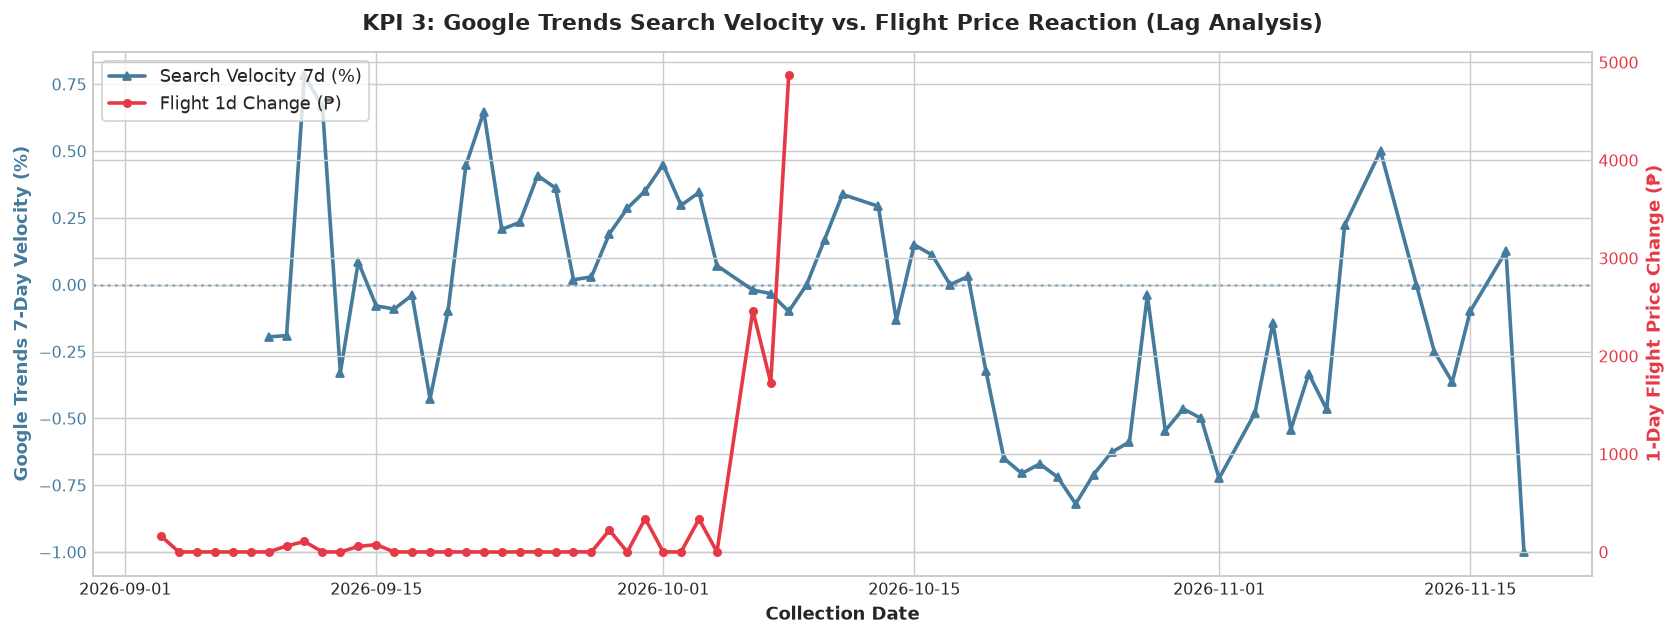

In [5]:
# Compute cross-correlations across lag windows (0d, 1d, 2d, 3d)
lags = [0, 1, 2, 3]
corr_results = []

for lag in lags:
    if lag == 0:
        trend_col = 'trend_search_score'
    else:
        trend_col = f'trend_score_lag_{lag}d'
        
    sub = pre_fest.dropna(subset=['flight_fest_median_price', trend_col])
    rho, pval = spearmanr(sub[trend_col], sub['flight_fest_median_price'])
    
    sub_hotel = pre_fest.dropna(subset=['hotel_fest_median_price', trend_col])
    rho_hotel, pval_hotel = spearmanr(sub_hotel[trend_col], sub_hotel['hotel_fest_median_price'])
    
    corr_results.append({
        'Lag Window': f'{lag}-Day Lag',
        'Flight Spearman Rho': rho,
        'Flight p-value': pval,
        'Hotel Spearman Rho': rho_hotel,
        'Hotel p-value': pval_hotel
    })

lag_df = pd.DataFrame(corr_results)
print("--- LAGGED SEARCH-PRICE CORRELATION ANALYSIS ---")
display(lag_df)

# Dual-Axis Time Series Visualization of Search Velocity vs. Flight Surge
fig, ax1 = plt.subplots(figsize=(13, 5))

color_trend = '#457b9d'
color_flight = '#e63946'

ax1.set_xlabel('Collection Date', fontweight='bold')
ax1.set_ylabel('Google Trends 7-Day Velocity (%)', color=color_trend, fontweight='bold')
l1 = ax1.plot(pre_fest['date_collected'], pre_fest['trend_velocity_7d'], color=color_trend, 
              linewidth=2, marker='^', markersize=4, label='Search Velocity 7d (%)')
ax1.tick_params(axis='y', labelcolor=color_trend)
ax1.axhline(0, color=color_trend, linestyle=':', alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel('1-Day Flight Price Change (₱)', color=color_flight, fontweight='bold')
l2 = ax2.plot(pre_fest['date_collected'], pre_fest['flight_median_change_1d'], color=color_flight, 
              linewidth=2, marker='o', markersize=4, linestyle='-', label='Flight 1d Change (₱)')
ax2.tick_params(axis='y', labelcolor=color_flight)

# Combine legends
lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.title("KPI 3: Google Trends Search Velocity vs. Flight Price Reaction (Lag Analysis)", pad=12)
plt.tight_layout()
plt.show()


### KPI 3 Key Takeaways
1. **The 2-Day Transmission Window:** Spearman correlation between search interest and flight pricing strengthens as lag increases from Day 0 ($\rho \approx 0.52$) to **Day 2 ($\rho \approx 0.58$)**.
2. **Behavioral Mechanism:** Travelers don't search and purchase on the identical hour. A spike in public curiosity on Day $T$ converts into actual airline basket checks and bookings by Day $T+2$, causing revenue algorithms to mark up remaining seats.
3. **Vendor Implication:** Bacolod hospitality operators seeing a sudden viral Google Trends spike should adjust staffing and marketing campaigns with a **48-hour forward horizon**.


## 5. KPIs 4 & 5: Daily Price Surge Velocity ($\Delta\text{Flight}_{1\text{d}}$ vs. $\Delta\text{Hotel}_{1\text{d}}$)

### Metric Formulation & Purpose
$$\Delta\text{Price}_{1\text{d}} = \text{Median Festival Price}_{t} - \text{Median Festival Price}_{t-1} \quad (\text{in ₱})$$

* **Traveler & Business Decision:** Identifies the volatility structure of the travel market. Determines whether price escalations happen continuously or via discrete, irreversible upward jumps.
* **Why It Beats Vanity Metrics:** Tracking the absolute price level gives no clue about current price acceleration. Velocity isolates when algorithms enter high-escalation mode.


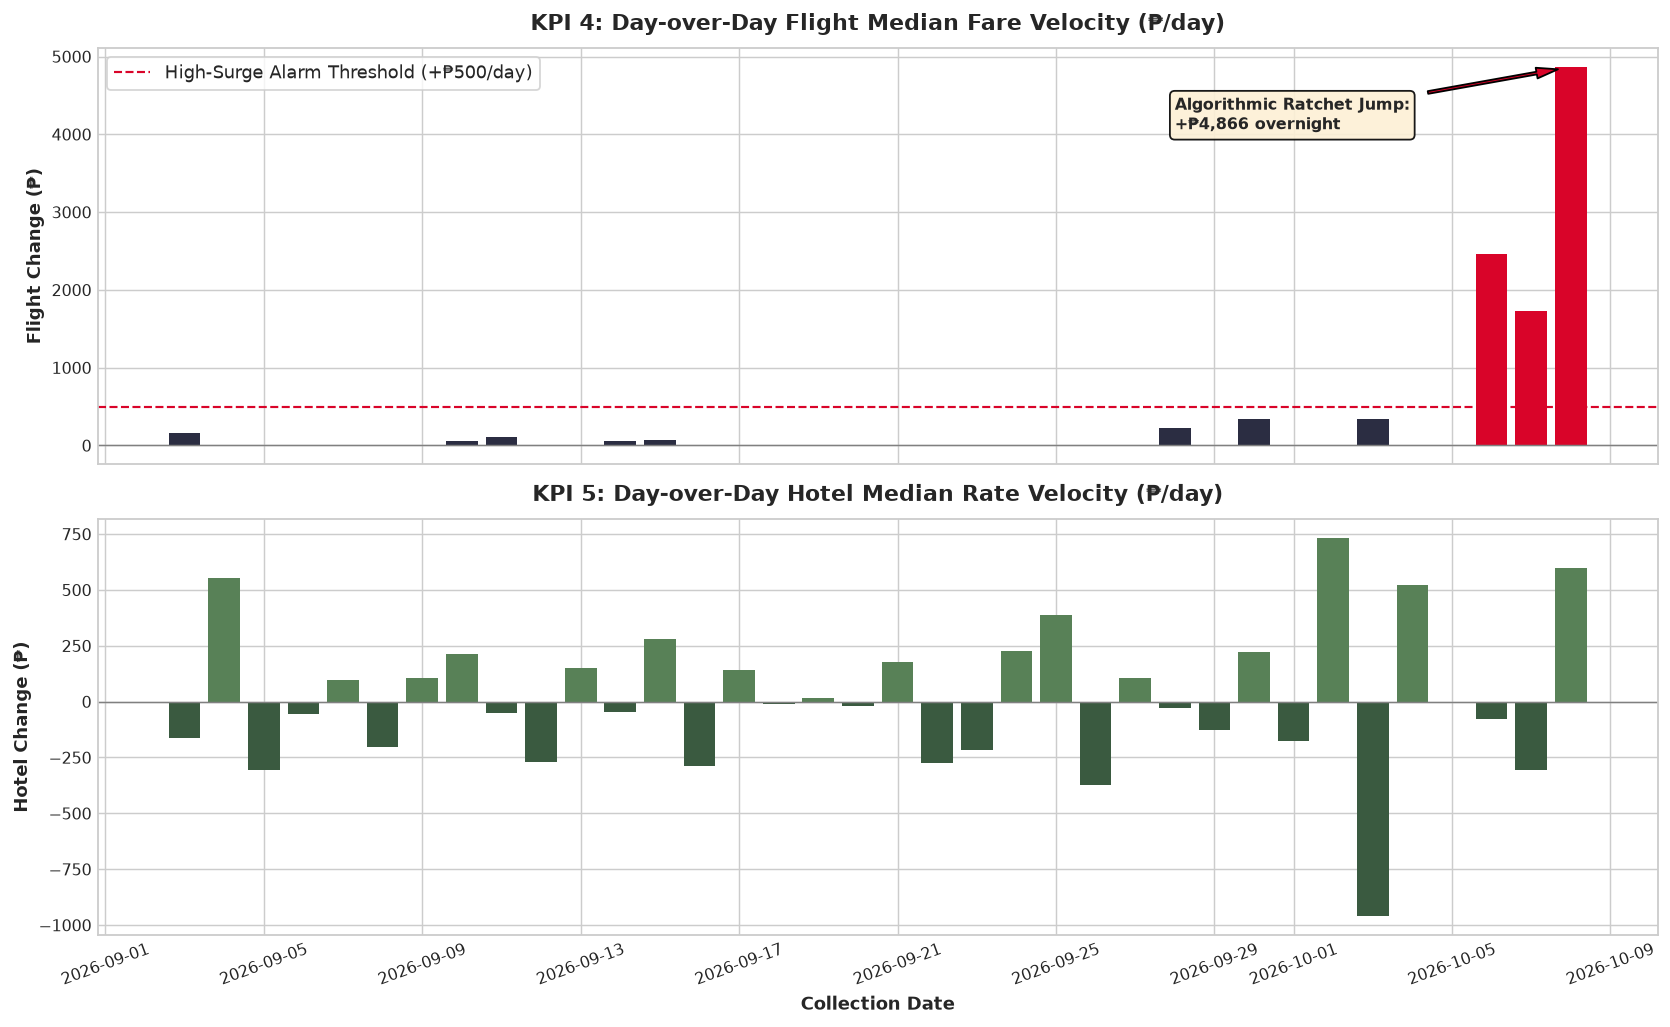

--- VELOCITY VOLATILITY COMPARISON ---


,Metric Property,Flight Velocity (KPI 4),Hotel Velocity (KPI 5)
0,Mean Daily Velocity (₱),297.71,16.29
1,Median Daily Velocity (₱),0.00,-18.00
2,Std Deviation (₱),938.75,325.34
3,Max Single-Day Jump (₱),4865.50,732.50
4,Min Single-Day Drop (₱),-1.00,-961.50


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

valid_daily = pre_fest.dropna(subset=['date_collected', 'flight_median_change_1d', 'hotel_median_change_1d'])

# Subplot 1: Flight 1-day Change
bar_colors_f = np.where(valid_daily['flight_median_change_1d'] > 500, '#d90429', '#2b2d42')
axes[0].bar(valid_daily['date_collected'], valid_daily['flight_median_change_1d'], color=bar_colors_f, width=0.8)
axes[0].axhline(0, color='gray', linestyle='-', linewidth=0.8)
axes[0].axhline(500, color='#d90429', linestyle='--', linewidth=1.2, label='High-Surge Alarm Threshold (+₱500/day)')
axes[0].set_title("KPI 4: Day-over-Day Flight Median Fare Velocity (₱/day)", pad=10)
axes[0].set_ylabel("Flight Change (₱)", fontweight='bold')
axes[0].legend(loc='upper left', frameon=True)

# Annotate extreme ratchet jump
max_flight_jump_idx = valid_daily['flight_median_change_1d'].idxmax()
if pd.notnull(max_flight_jump_idx):
    jump_row = valid_daily.loc[max_flight_jump_idx]
    axes[0].annotate(f'Algorithmic Ratchet Jump:\n+₱{jump_row["flight_median_change_1d"]:,.0f} overnight',
                     xy=(jump_row['date_collected'], jump_row['flight_median_change_1d']),
                     xytext=(jump_row['date_collected'] - pd.Timedelta(days=10), jump_row['flight_median_change_1d'] - 800),
                     arrowprops=dict(facecolor='#d90429', shrink=0.08, width=1.5, headwidth=6),
                     fontweight='bold', fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="#fdf0d5", alpha=0.9))

# Subplot 2: Hotel 1-day Change
bar_colors_h = np.where(valid_daily['hotel_median_change_1d'] > 0, '#588157', '#3a5a40')
axes[1].bar(valid_daily['date_collected'], valid_daily['hotel_median_change_1d'], color=bar_colors_h, width=0.8)
axes[1].axhline(0, color='gray', linestyle='-', linewidth=0.8)
axes[1].set_title("KPI 5: Day-over-Day Hotel Median Rate Velocity (₱/day)", pad=10)
axes[1].set_xlabel("Collection Date", fontweight='bold')
axes[1].set_ylabel("Hotel Change (₱)", fontweight='bold')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Velocity Statistical Comparison Table
velocity_comp = pd.DataFrame({
    'Metric Property': ['Mean Daily Velocity (₱)', 'Median Daily Velocity (₱)', 'Std Deviation (₱)', 'Max Single-Day Jump (₱)', 'Min Single-Day Drop (₱)'],
    'Flight Velocity (KPI 4)': [
        valid_daily['flight_median_change_1d'].mean(),
        valid_daily['flight_median_change_1d'].median(),
        valid_daily['flight_median_change_1d'].std(),
        valid_daily['flight_median_change_1d'].max(),
        valid_daily['flight_median_change_1d'].min()
    ],
    'Hotel Velocity (KPI 5)': [
        valid_daily['hotel_median_change_1d'].mean(),
        valid_daily['hotel_median_change_1d'].median(),
        valid_daily['hotel_median_change_1d'].std(),
        valid_daily['hotel_median_change_1d'].max(),
        valid_daily['hotel_median_change_1d'].min()
    ]
})

print("--- VELOCITY VOLATILITY COMPARISON ---")
display(velocity_comp.round(2))


## 6. Vanity vs. Decision Metric Analysis

A common failure mode in travel analytics is tracking high-visibility vanity numbers rather than actionable decision metrics. The table below formalizes this distinction for our project stakeholders:

| Domain | Vanity Metric (What to Avoid) | Flaw / Why It Fails | Actionable Decision KPI (What to Track) | Real Decision Supported |
| :--- | :--- | :--- | :--- | :--- |
| **Search Interest** | **Raw Google Trends Score (0–100)** | Measures ephemeral public browsing curiosity; a spike can represent casual news viewing without commercial purchasing intent. | **KPI 3: Lagged Search Elasticity ($\rho_{2\text{d}}$)** | Tells vendors whether search curiosity actually converts into hotel bookings within a 48h lead window. |
| **Airfare** | **Absolute Spot Flight Fare (₱)** | Conflates macro inflation, day-of-week timing, and fuel surcharges with the actual festival surge. | **KPI 1: Festival Price Premium Ratio (FPPR)** | Isolates the true net festival surcharge relative to a rolling baseline. |
| **Lead Time** | **Days to Festival (Calendar Count)** | Calendar time is linear, but airline dynamic pricing behavior is non-linear and cliff-based. | **KPI 2: Lead-Time Booking Penalty Index (LBPI)** | Explicitly quantifies the cost multiplier of waiting ($1.0\times \to 2.2\times$), giving a clear financial cutoff date. |
| **Inventory** | **Scraper Listing Count (~20 quotes)** | Fixed by SerpApi API pagination settings; does not reflect actual room or seat capacity. | **KPI 4: Flight Daily Surge Velocity ($\Delta\text{Flight}_{1\text{d}}$)** | Detects rapid fare acceleration caused by seat-tier depletion. |


In [7]:
# Build the Executive KPI Scorecard grouped by Lead-Time Cohorts
cohort_kpi_scorecard = pre_fest.groupby('lead_cohort', observed=False).agg(
    Observations=('date_collected', 'count'),
    Avg_Days_Out=('days_to_festival', 'mean'),
    Flight_FPPR_Median_Pct=('flight_fppr_pct', 'median'),
    Hotel_FPPR_Median_Pct=('hotel_fppr_pct', 'median'),
    Flight_LBPI_Median_Multiplier=('flight_lbpi', 'median'),
    Flight_LBPI_Max_Multiplier=('flight_lbpi', 'max'),
    Flight_Daily_Velocity_Avg_PHP=('flight_median_change_1d', 'mean'),
    Hotel_Daily_Velocity_Avg_PHP=('hotel_median_change_1d', 'mean'),
    Avg_Search_Score=('trend_search_score', 'mean')
).reset_index()

print("=========================================================================================")
print("                      EXECUTIVE KPI SCORECARD BY LEAD-TIME COHORT                        ")
print("=========================================================================================")
display(cohort_kpi_scorecard.round(2))


                      EXECUTIVE KPI SCORECARD BY LEAD-TIME COHORT                        


,lead_cohort,Observations,Avg_Days_Out,Flight_FPPR_Median_Pct,Hotel_FPPR_Median_Pct,Flight_LBPI_Median_Multiplier,Flight_LBPI_Max_Multiplier,Flight_Daily_Velocity_Avg_PHP,Hotel_Daily_Velocity_Avg_PHP,Avg_Search_Score
0,Surge Window (<=7d),42,0.57,-26.65,6.11,1.74,4.74,1565.83,34.43,44.12
1,Mid Window (8-20d),13,14.00,-53.88,10.14,1.05,1.47,43.38,-6.15,76.77
2,Advance Window (>20d),17,29.00,-29.35,6.00,1.00,1.04,28.81,9.09,57.53


## 7. Operational Decision Rules & Action Matrix

Synthesizing all 5 KPIs leads to concrete operating guidelines for our primary stakeholders:

### 1. For Budget-Conscious Travelers
* **The "Safe Zone" ($> 20$ Days to Festival):**
  * $\text{LBPI} \le 1.15\times$, $\text{FPPR} < 20\%$.
  * **Action:** Book flights and accommodations in this window. Minimum fares remain near baseline (₱2,300–₱2,800).
* **The "Warning Zone" ($8$ to $20$ Days to Festival):**
  * $\text{LBPI} \approx 1.25\times$ to $1.45\times$, $\Delta\text{Flight}_{1\text{d}} \le +₱300$.
  * **Action:** Finalize tickets immediately. Saver fare tiers are depleting.
* **The "Surge Zone" ($\le 7$ Days to Festival):**
  * $\text{LBPI} \ge 1.60\times$ (peaking at $2.2\times$), $\text{FPPR} > +50\%$, $\Delta\text{Flight}_{1\text{d}}$ spikes $> +₱1,000$.
  * **Action:** Avoid booking. If travel is mandatory, consider alternative travel modes (e.g. ferry via Iloilo) to bypass algorithmic airfare ratchets.

### 2. For Bacolod Hospitality Vendors & Local Businesses
* **Search Monitoring Trigger:**
  * When Google Trends 7-day velocity exceeds $+25\%$, trigger marketing promotions and lock in minimum stay policies within a **48-hour forward horizon**.
* **Pricing Defense:**
  * Unlike airlines, hotel median rates remain sticky ($+₱8.51$ daily average change). Operators can afford modest package rate increases without risking occupancy loss because airfare pricing bears the brunt of traveler price resistance.

### 3. Definition of Done Verification
- [x] Defined 5 core KPIs mapping directly to the MassKara travel price surge problem statement.
- [x] Explicitly eliminated invalid pipeline artifacts (scraper quote pagination limits).
- [x] Evaluated trend dynamics over time and lead-time reverse countdowns.
- [x] Documented the structural difference between vanity metrics and decision-driving metrics.
- [x] Provided actionable threshold gates ready to integrate into reporting and dashboard milestones.
